In [353]:
import math
import random

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [354]:
from graphviz import Digraph


def trace(root):
    # builds a set of all nodes and edges in a graph
    nodes, edges = set(), set()

    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)

    build(root)
    return nodes, edges


def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})  # LR = left to right

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        # for any value in the graph, create a rectangular ('record') node for it
        dot.node(name=uid, label="{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
        if n._op:
            # if this value is a result of some operation, create an op node for it
            dot.node(name=uid + n._op, label=n._op)
            # and connect this node to it
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        # connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot


In [355]:
import math


class Value:

    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"Value(data={self.data}, label={self.label})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')

        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad

        out._backward = _backward

        return out

    def __radd__(self, other):  # other + self  (needed for sum())
        return self + other

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')

        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad

        out._backward = _backward

        return out

    def __rmul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        return self * other

    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only supporting ints and floats"
        out = Value(self.data ** other, (self,), f'^{other}')

        def _backward():
            self.grad += other * (self.data ** (other - 1)) * out.grad

        out._backward = _backward

        return out

    def __truediv__(self, other):
        return self * other ** -1

    def __neg__(self):
        return self * -1

    def __sub__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        return self + (-other)

    def __rsub__(self, other):  # other - self  (needed for float - Value)
        return other + (-self)

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self,), 'exp')

        def _backward():
            self.grad += math.exp(x) * out.grad # the derivative of e^x is e^x :)

        out._backward = _backward

        return out

    def tanh(self):
        x = self.data
        t = math.tanh(x)
        out = Value(t, (self,), 'tanh')

        def _backward():
            self.grad += (1 - t ** 2) * out.grad

        out._backward = _backward

        return out

    # so we don't have to manually call node._backward() on every non leaf node
    # we build a function that creates topological sort of the nodes and then call on each node ._backward()
    # starting from the root

    def backward(self):
        topo = []
        visited = set()

        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)

        build_topo(self)

        self.grad = 1.0

        for node in reversed(topo):
            node._backward()

In [356]:
# This is time we will implement tanh fully
# inputs x1,x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias of the neuron
b = Value(6.8813735870195432, label='b')
# x1*w1 + x2*w2 + b
x1w1 = x1 * w1;
x1w1.label = 'x1*w1'
x2w2 = x2 * w2;
x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2;
x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b;
n.label = 'n'

#o = n.tanh();
e = (2*n).exp(); e.label = 'e'
o = (e - 1)/(e+1)
o.label = 'o'

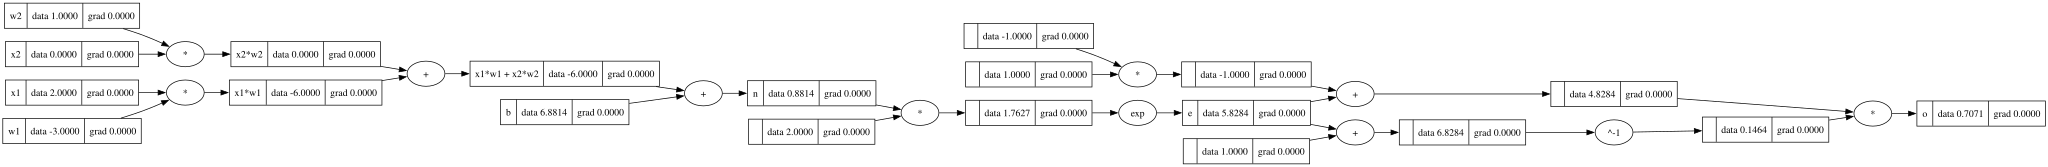

In [357]:
draw_dot(o)

In [358]:
# o._backward()
# n._backward()
# x1w1x2w2._backward()
# x1w1._backward()
# x2w2._backward() same as
o.backward()

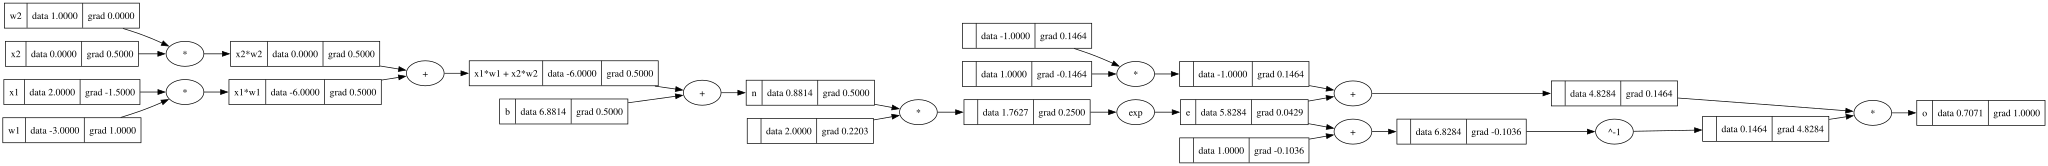

In [359]:
draw_dot(o) # 1:27 of the video

In [360]:
# ok let's now use pytorch to do the same thing
import torch

In [361]:
# The only difference is that we will use tensors instead of this 'Value' objects
x1 = torch.Tensor([2.0]).double(); x1.requires_grad = True;
x2 = torch.Tensor([0.0]).double(); x2.requires_grad = True;
w1 = torch.Tensor([-3.0]).double(); w1.requires_grad = True;
w2 = torch.Tensor([1.0]).double(); w2.requires_grad = True;

b = torch.Tensor([6.8813735870195432]).double(); b.requires_grad = True;
n = x1*w1 + x2*w2 + b;
n.retain_grad() # By default, PyTorch computes gradients for intermediate tensors, but only stores for leaf tensors
o = torch.tanh(n)

o.backward()
print(o)
print(n.grad.item())

tensor([0.7071], dtype=torch.float64, grad_fn=<TanhBackward0>)
0.5000001283844369


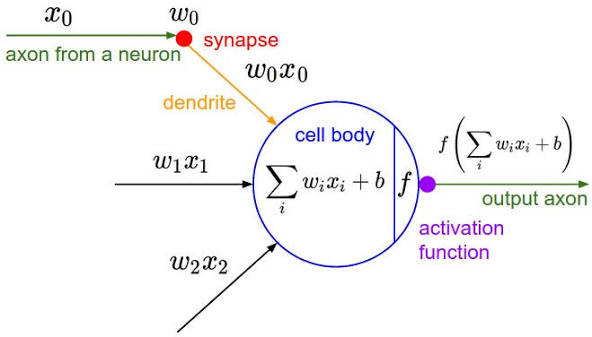

In [362]:
# Now let's recreate this neuron
import random

class Neuron:

    def __init__(self, number_of_inputs):
        self.w = [Value(random.uniform(-1,1)) for _ in range (number_of_inputs)]
        self.b = Value(random.uniform(-1,1))

    def __call__(self, x):
        # for each synapse do weight*x and then add the bias
        act = sum((wi * xi for wi, xi in zip(self.w,x)), self.b)
        print(act)
        out = act.tanh()
        return out

x = [2.0, 3.0]
n = Neuron(2)
n(x)

Value(data=4.167367558024903, label=)


Value(data=0.9995200496704175, label=)

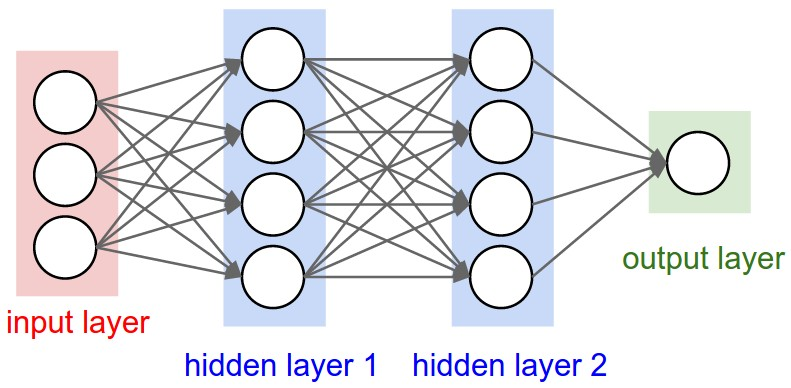

In [363]:
# let's reproduce this picture in code
# Neuron: computes tanh(w*x + b)
# Layer: a group of neurons
# MLP: a sequence of layers


class Neuron:
    def __init__(self, n_inputs):
        self.weights = [Value(random.uniform(-1, 1), label='weight') for _ in range(n_inputs)]
        self.bias = Value(random.uniform(-1, 1), label='bias')

    def __call__(self, x):
        return sum((xi * wi for xi, wi in zip(x, self.weights)), self.bias).tanh()

    def parameters(self):
        return self.weights + [self.bias]

class Layer:
    def __init__(self, n_inputs, n_outputs):
        self.neurons = [Neuron(n_inputs) for _ in range(n_outputs)]

    def __call__(self, x):
        outs = [neuron(x) for neuron in self.neurons]
        return outs[0] if len(outs) == 1 else outs

    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]

#Multi Layer Perceptron
class MLP:
    def __init__(self, n_inputs, layer_sizes: list[int]):
        self.layers = []

        for n_outputs in layer_sizes:
            self.layers.append(Layer(n_inputs, n_outputs))
            n_inputs = n_outputs

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]


x = [11, 22]
mlp = MLP(2, [2, 2, 1])
output = mlp(x)

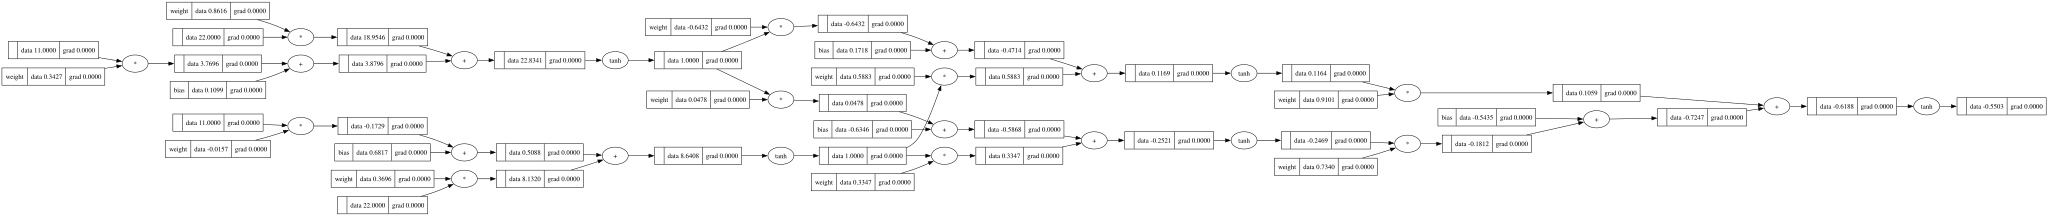

In [364]:
draw_dot(output)

In [365]:
# now let's have sequence of inputs and sequence of desired outputs
mlp = MLP(3, [4,4,1])

xs = [
    [2.0,3.0,-1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0],
]

ys = [1.0, -1.0, -1.0, 1.0] # desired outputs for each input array
ypred = [mlp(x) for x in xs]
ypred

[Value(data=0.04750357991608812, label=),
 Value(data=0.6927675513343318, label=),
 Value(data=0.9121448733047846, label=),
 Value(data=0.6319185089738181, label=)]

In [366]:
# To adjust our mlp so it produces the outputs
# we can:
#   1. Calculate the gradients
#   2. Based on them adjust the weights on each layer
# Ok it will be easy to do if we had single input-output but we have many so how do we optimize for all of them at once???

# when a single weight is used in two expressions simultaneously
# we can just find the loss for each sqrt it and sum them
# this way the grad will be calculated based on how it's related to the final loss

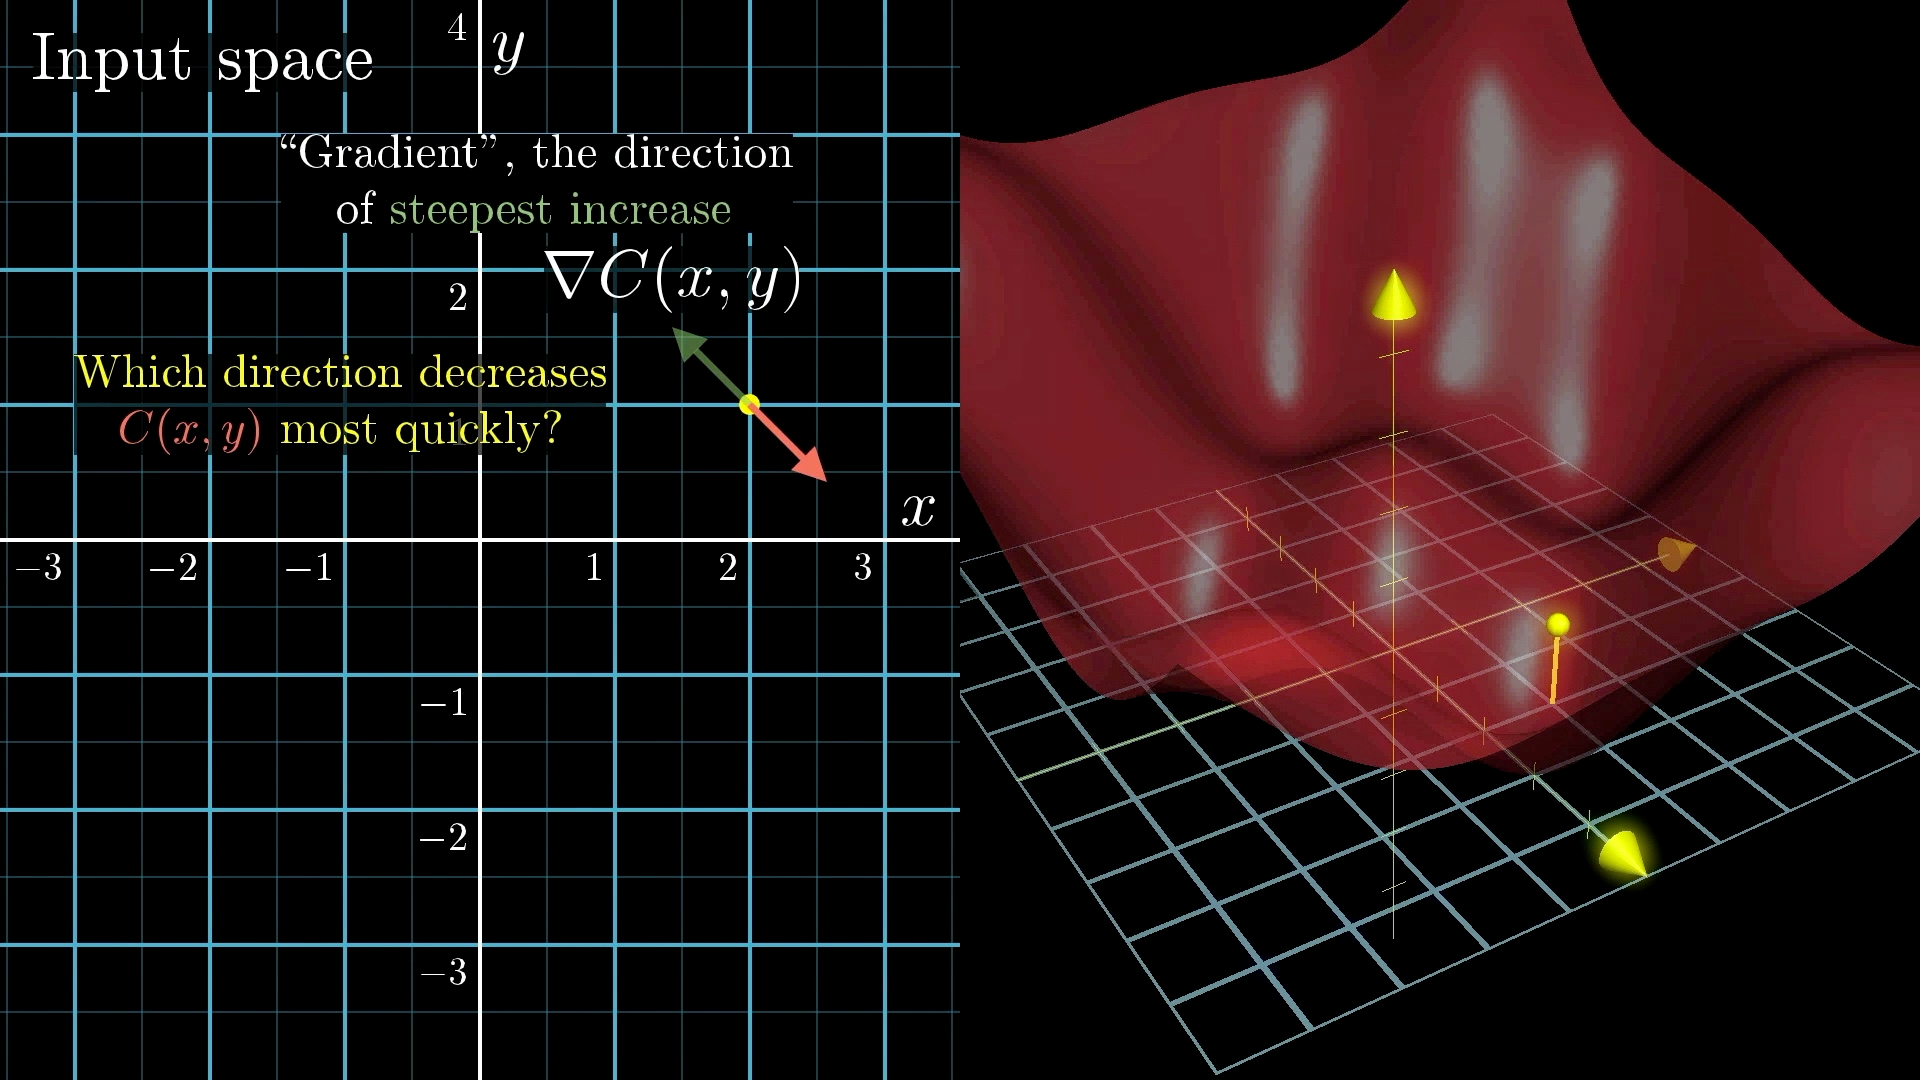

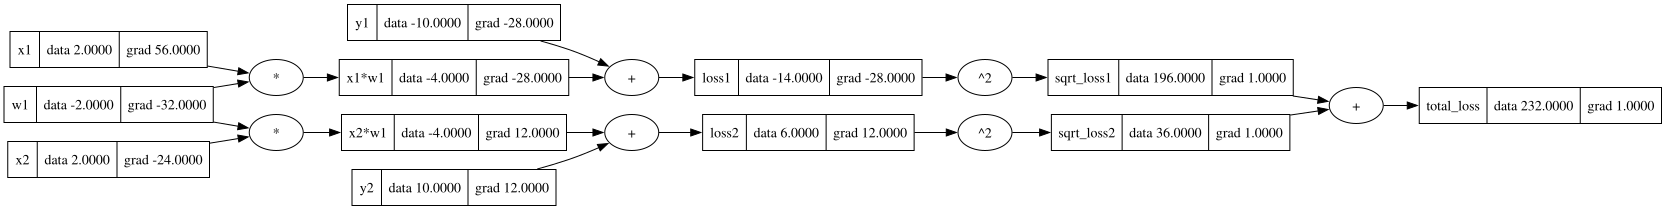

In [367]:
# Let's check how gradient stacking exactly works
# inputs x1,x2
x1 = Value(2.0, label='x1')
x2 = Value(2.0, label='x2')
# weights w1,w2
w1 = Value(-2, label='w1') # make it 0 and grad becomes 0 too
# x1*w1 + x2*w2 + b
x1w1 = x1 * w1;
x1w1.label = 'x1*w1'
x2w1 = x2 * w1;
x2w1.label = 'x2*w1'

y1 = Value(-10, label='y1') # so the target are in the opposite direction
y2 = Value(10, label='y2') # that's why the best loss we can get is 200 everything else is worse

loss1 = x1w1 + y1; loss1.label = 'loss1'
loss2 = x2w1 + y2; loss2.label = 'loss2'

sqrt_loss1 = loss1**2; sqrt_loss1.label = 'sqrt_loss1'
sqrt_loss2 = loss2**2; sqrt_loss2.label = 'sqrt_loss2'

total_loss = sqrt_loss1 + sqrt_loss2; total_loss.label = 'total_loss'
total_loss.backward()
draw_dot(total_loss)

In [ ]:
# Ok now let's do this
mlp = MLP(3, [4, 4, 1])

xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0] # desired outputs for each input array


In [ ]:
ypreds = [mlp(x) for x in xs] # forward pass
total_loss = sum((y - ypred)**2 for y, ypred in zip(ys, ypreds))
total_loss.backward()
total_loss


In [ ]:
for p in mlp.parameters():
    p.data += -0.01 * p.grad


In [ ]:
# forward pass again to see if the loss went down
ypreds = [mlp(x) for x in xs]
total_loss = sum((y - ypred)**2 for y, ypred in zip(ys, ypreds))
total_loss


In [ ]:
for k in range(200):

    # forward pass
    ypreds = [mlp(x) for x in xs]
    loss = sum((y - ypred)**2 for y, ypred in zip(ys, ypreds))

    # set parameters grads to 0 (we have to make sure the intermediate  nodes grads are not retained)
    # backward pass
    for p in mlp.parameters():
        p.grad = 0.0
    loss.backward()

    for p in mlp.parameters():
        p.data += -0.1 * p.grad

    print(k, loss.data)


In [ ]:
ypreds
